 disease_type    → list, ['Impacted', 'Caries', 'Periapical Lesion', 'Deep Caries'] (disease.values() se)

disease_count   → list, [604, 2189, 158, 578] — har disease ki image count (output/ folder se)

transform       → PyTorch recipe: resize + tensor-convert, images pe apply hota hai


train_dataset   → PyTorch ImageFolder object, "dataset/train" se, .classes attribute isमें hai


val_dataset     → PyTorch ImageFolder object, "dataset/val" se


train_loader    → batches (32-32) mein train_dataset deta hai, shuffled


val_loader      → batches deta hai val_dataset se, bina shuffle


 model           → MobileNetV2, pretrained, last layer 4-class ke liye badla hua

criterion       → loss function (CrossEntropyLoss), "kitni galti hui" measure karta hai

 optimizer       → Adam, "weights kaise update karo" decide karta hai
 
device          → "mps" ya "cpu" — kaha calculations honge

In [1]:
import os
import json
import matplotlib.pyplot as plt
import numpy as np


In [2]:
data_path = os.path.join("training_data","quadrant-enumeration-disease")
json_file=os.path.join(data_path,"train_quadrant_enumeration_disease.json")
with open(json_file , "r") as f:
    json_data=json.load(f)

In [3]:
disease={}
for d in json_data["categories_3"]:
    disease[d["id"]]= d["name"]
print(disease)

{0: 'Impacted', 1: 'Caries', 2: 'Periapical Lesion', 3: 'Deep Caries'}


In [4]:
output_base = "output"

In [5]:
disease_type = list(disease.values())
disease_count = []
for d in disease_type:
    folder_path = os.path.join(output_base, d)
    count = len(os.listdir(folder_path))
    disease_count.append(count)
print(disease_count)


[604, 2189, 158, 578]


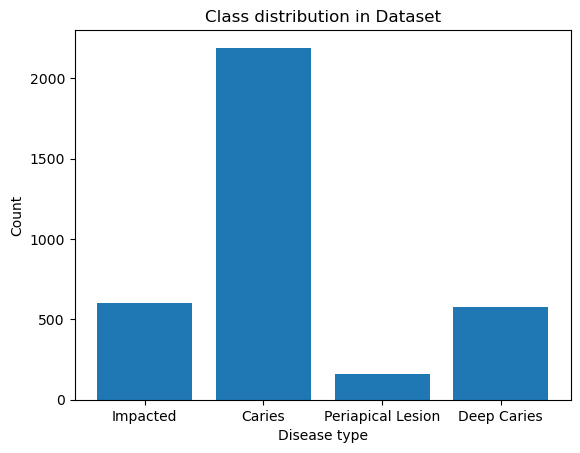

In [6]:
#  making bar chart of the disease count vs disease type
plt.bar(disease_type,disease_count)
plt.xlabel("Disease type")
plt.ylabel("Count")
plt.title("Class distribution in Dataset")
plt.show()

# Using Transfer Learing as our model data is small and huge differences between classes. 

In [7]:
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms, datasets, models

In [8]:
#  creating transforms parameters
IMAGE_SIZE = 224
transform= transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),
    transforms.ToTensor(),
    ])

In [9]:
# dataset 

train_dataset=datasets.ImageFolder("dataset/train", transform=transform)
val_dataset=datasets.ImageFolder("dataset/val",transform=transform)
print(train_dataset.classes)

['Caries', 'Deep Caries', 'Impacted', 'Periapical Lesion']


In [10]:
# dataloader
BATCH_SIZE= 32
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE,shuffle=True)
val_loader= torch.utils.data.DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False )


In [11]:
# load pretrained model
model=models.mobilenet_v2(weights="IMAGENET1K_V1")
model.classifier[1]=nn.Linear(in_features=1280,out_features=4)
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)


In [12]:
# freeze parameters 
for param in model.features.parameters():
    param.requires_grad = False

In [13]:
# loss function
criterion= nn.CrossEntropyLoss()

In [14]:
# optimizer
optimizer=torch.optim.Adam(model.classifier.parameters(),lr=0.001)

In [15]:
# device run
device= torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(device)
model=model.to(device)

mps


In [16]:
# training loop
EPOCH=5
for epoch in range(EPOCH):
    model.train()
    running_loss=0.0
    for images, labels in train_loader:
        images,labels=images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        output=model(images)
        loss=criterion(output,labels)
        loss.backward()
        optimizer.step()
        
        running_loss +=loss.item()
        
    print(f"Epoch {epoch+1}/{EPOCH}, loss:{running_loss/len(train_loader):.4f}")

Epoch 1/5, loss:0.8954
Epoch 2/5, loss:0.7466
Epoch 3/5, loss:0.7011
Epoch 4/5, loss:0.6751
Epoch 5/5, loss:0.6603


In [17]:
# overall accuracy
model.eval()
correct=0
total=0
with torch.no_grad():
    for images,labels in val_loader:
        images,labels= images.to(device), labels.to(device)
        output=model(images)
        _,predicted=torch.max(output,1)
        total += labels.size(0)
        correct += (predicted==labels).sum().item()
print(f"Overall validation accuracy:{100*correct/total:.2f}%")

Overall validation accuracy:77.09%


In [18]:
from sklearn.metrics import classification_report
model.eval()
all_pred=[]
all_labels=[]
with torch.no_grad():
    for images,labels in val_loader:
        images,labels= images.to(device),labels.to(device)
        output=model(images)
        _,predicted= torch.max(output,1)
        all_pred.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
print(classification_report(all_labels,all_pred, target_names= train_dataset.classes))

                   precision    recall  f1-score   support

           Caries       0.76      0.96      0.85       438
      Deep Caries       0.71      0.22      0.33       116
         Impacted       0.86      0.80      0.83       121
Periapical Lesion       1.00      0.03      0.06        32

         accuracy                           0.77       707
        macro avg       0.83      0.50      0.52       707
     weighted avg       0.78      0.77      0.72       707



As recall score for deep caries and periapiacl lesion is very low, we will do class weighting and 
# rerun it  

In [19]:

#  we will extract count of train images in every class
train_d_count=[]
for n in train_dataset.classes:
    count=len(os.listdir(os.path.join("dataset/train", n)))
    train_d_count.append(count)
print(train_d_count)
    

[1751, 462, 483, 126]


In [20]:
# weight for class formula = TOTAL IMAGES/NUM OF CLASSES* IMG IN THAT CLASS)
total_img= sum(train_d_count)
num_of_classes= len(train_d_count)
class_weights=[]
for count in train_d_count:
    weight= total_img/(num_of_classes* count)
    class_weights.append(weight)
print(class_weights)


[0.4029126213592233, 1.527056277056277, 1.4606625258799173, 5.599206349206349]


In [21]:
model= models.mobilenet_v2(weights="IMAGENET1K_V1")
model.classifier[1]=nn.Linear(in_features= 1280,out_features=4)

In [22]:
for param in model.features.parameters():
    param.requires_grad=False

In [23]:
device=torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model=model.to(device)

In [24]:
# converting class_weights to tensor and updating criterion
class_weights_tensor = torch.tensor(class_weights).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=0.001)

In [25]:
#  training loop
EPOCHS=5
for epoch in range(EPOCHS):
    model.train()
    running_loss=0.0
    for images,labels in train_loader:
        images, labels = images.to(device),labels.to(device)
        optimizer.zero_grad()
        output=model(images)
        loss=criterion(output,labels)
        loss.backward()
        optimizer.step()
        running_loss +=loss.item()
    print(f"Epoch {epoch+1}/{EPOCH}, loss:{running_loss/len(train_loader):.4f}")

Epoch 1/5, loss:1.1857
Epoch 2/5, loss:0.9756
Epoch 3/5, loss:0.9149
Epoch 4/5, loss:0.8668
Epoch 5/5, loss:0.8377


In [26]:
# evaluation
from sklearn.metrics import classification_report

model.eval()
all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))


                   precision    recall  f1-score   support

           Caries       0.84      0.62      0.72       438
      Deep Caries       0.35      0.41      0.38       116
         Impacted       0.74      0.95      0.83       121
Periapical Lesion       0.19      0.56      0.28        32

         accuracy                           0.64       707
        macro avg       0.53      0.63      0.55       707
     weighted avg       0.72      0.64      0.66       707



Will change the weight loss  as precision is reduced drastically for periapical and deep caries  and recall rate for caries is also reduced so we will update and 
# rerun it

In [27]:

model=models.mobilenet_v2(weights= "IMAGENET1K_V1")
model.classifier[1]=nn.Linear(in_features=1280, out_features=4)


In [28]:
for param in model.features.parameters():
    param.requires_grad=False

In [29]:
device = torch.device("mps" if torch.backends.mps.is_available() else("cpu"))
model=model.to(device)


In [30]:
# converting classes weights 
class_weights_softer = [w ** 0.5 for w in class_weights]
class_weights_tensor = torch.tensor(class_weights_softer).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=0.001)

In [31]:
EPOCHS=5
for epoch in range(EPOCHS):
    model.train()
    running_loss=0.0
    for images,labels in train_loader:
        images,labels=images.to(device),labels.to(device)
        optimizer.zero_grad()
        output=model(images)
        loss=criterion(output,labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch:{epoch+1}/{EPOCH},  Loss={running_loss/len(train_loader):.4f}")
  

Epoch:1/5,  Loss=1.1331
Epoch:2/5,  Loss=0.9208
Epoch:3/5,  Loss=0.8634
Epoch:4/5,  Loss=0.8125
Epoch:5/5,  Loss=0.8253


In [32]:
# evaluation
model.eval()
all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

                   precision    recall  f1-score   support

           Caries       0.84      0.61      0.71       438
      Deep Caries       0.29      0.50      0.37       116
         Impacted       0.73      0.97      0.83       121
Periapical Lesion       0.21      0.16      0.18        32

         accuracy                           0.64       707
        macro avg       0.52      0.56      0.52       707
     weighted avg       0.70      0.64      0.65       707



# rerun updating weights again

In [33]:
model=models.mobilenet_v2(weights= "IMAGENET1K_V1")
model.classifier[1]=nn.Linear(in_features=1280, out_features=4)

In [34]:
for param in model.features.parameters():
    param.requires_grad= False

In [35]:
device= torch.device("mps" if torch.backends.mps.is_available() else("cpu"))
model=model.to(device)

In [36]:
class_weights_medium = [w ** 0.75 for w in class_weights]
class_weights_tensor = torch.tensor(class_weights_medium).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=0.001)

In [37]:
EPOCH= 5
for epoch in range(EPOCH):
    model.train()
    running_loss=0.0
    for images,labels in train_loader:
        images,labels=images.to(device),labels.to(device)
        optimizer.zero_grad()
        output=model(images)
        loss=criterion(output,labels)
        loss.backward()
        optimizer.step()
        running_loss +=loss.item()
    print(f"Epoch:{epoch+1}/{EPOCH},Loss:{running_loss/len(train_loader):.4f}")

Epoch:1/5,Loss:1.1639
Epoch:2/5,Loss:1.0043
Epoch:3/5,Loss:0.9142
Epoch:4/5,Loss:0.8576
Epoch:5/5,Loss:0.8335


In [38]:
model.eval()
all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

                   precision    recall  f1-score   support

           Caries       0.87      0.41      0.56       438
      Deep Caries       0.30      0.44      0.36       116
         Impacted       0.63      0.96      0.76       121
Periapical Lesion       0.16      0.72      0.26        32

         accuracy                           0.52       707
        macro avg       0.49      0.63      0.48       707
     weighted avg       0.71      0.52      0.55       707



as weights updation  are not working will do data augmentation here
# rerun

In [39]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

In [40]:
train_dataset=datasets.ImageFolder("dataset/train",transform=train_transform)
val_dataset=datasets.ImageFolder("dataset/val",transform=val_transform)

In [41]:
train_loader=torch.utils.data.DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)
val_loader=torch.utils.data.DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False)

In [49]:
model = models.mobilenet_v2(weights="IMAGENET1K_V1")
model.classifier[1] = nn.Linear(in_features=1280, out_features=4)

for param in model.features.parameters():
    param.requires_grad = False

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=0.001)

EPOCH = 5
for epoch in range(EPOCH):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        output = model(images)
        loss = criterion(output, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch:{epoch+1}/{EPOCH}, Loss:{running_loss/len(train_loader):.4f}")

Epoch:1/5, Loss:0.9327
Epoch:2/5, Loss:0.8343
Epoch:3/5, Loss:0.7944
Epoch:4/5, Loss:0.7666
Epoch:5/5, Loss:0.7623


In [50]:
model.eval()
all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        output = model(images)
        _, predicted = torch.max(output, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

                   precision    recall  f1-score   support

           Caries       0.79      0.88      0.84       438
      Deep Caries       0.71      0.09      0.15       116
         Impacted       0.63      0.96      0.76       121
Periapical Lesion       0.38      0.25      0.30        32

         accuracy                           0.74       707
        macro avg       0.63      0.54      0.51       707
     weighted avg       0.73      0.74      0.69       707



# final rerun

In [52]:
# Dataset non-augmented transform 
train_dataset = datasets.ImageFolder("dataset/train", transform=transform)
val_dataset = datasets.ImageFolder("dataset/val", transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Model fresh
model = models.mobilenet_v2(weights="IMAGENET1K_V1")
model.classifier[1] = nn.Linear(in_features=1280, out_features=4)
for param in model.features.parameters():
    param.requires_grad = False
model = model.to(device)

# 0.75 weight
class_weights_medium = [w ** 0.75 for w in class_weights]
class_weights_tensor = torch.tensor(class_weights_medium).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=0.001)

# Training
EPOCH = 5
for epoch in range(EPOCH):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        output = model(images)
        loss = criterion(output, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch:{epoch+1}/{EPOCH}, Loss:{running_loss/len(train_loader):.4f}")

Epoch:1/5, Loss:1.1458
Epoch:2/5, Loss:0.9529
Epoch:3/5, Loss:0.8996
Epoch:4/5, Loss:0.8728
Epoch:5/5, Loss:0.8604


In [53]:
model.eval()
all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        output = model(images)
        _, predicted = torch.max(output, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

                   precision    recall  f1-score   support

           Caries       0.75      0.96      0.84       438
      Deep Caries       0.75      0.18      0.29       116
         Impacted       0.87      0.80      0.83       121
Periapical Lesion       0.43      0.09      0.15        32

         accuracy                           0.77       707
        macro avg       0.70      0.51      0.53       707
     weighted avg       0.76      0.77      0.72       707



In [54]:
torch.save(model.state_dict(), "caries_model.pth")
print("Model saved!")

Model saved!
